In [1]:
%load_ext autoreload

In [2]:
%autoreload 2

In [ ]:
import sys
import os

module_path = os.path.abspath(os.path.join('..', ''))
if module_path not in sys.path:
    sys.path.append(module_path)

# This enables imports like
# from rect_prune_ood.lib.prunging import X
import numpy as np
from rect_prune_ood.lib.util import get_top_level_path, plot_score_distributions, split_results
import matplotlib.pyplot as plt

## Plot confidences

In [37]:
id_data = np.load(get_top_level_path() + "/results/imagenet/baseline/id_imagenet.npy", allow_pickle=True).item()
ood_dtd = np.load(get_top_level_path() + "/results/imagenet/baseline/ood_dtd.npy", allow_pickle=True).item()
ood_places = np.load(get_top_level_path() + "/results/imagenet/baseline/ood_places.npy", allow_pickle=True).item()
ood_inat = np.load(get_top_level_path() + "/results/imagenet/baseline/ood_inat.npy", allow_pickle=True).item()
ood_sun = np.load(get_top_level_path() + "/results/imagenet/baseline/ood_sun.npy", allow_pickle=True).item()

In [71]:
# Find values where the prediction is correct 
def filter_correct(data):
    correct = []
    for i in range(len(data)):
        if data["prediction"][i] == data["label"][i]:
            correct.append(data["confidence"] * 100) 
    return np.concatenate(correct)

# Find values where the prediction is incorrect
id_data_correct = filter_correct(id_data)

In [72]:
id_data_bins = np.histogram(id_data_correct, bins=1000, range=(0, 100), density=False)
# ood_dtd_bins = np.histogram(ood_combined, bins=1000, range=(0, 100), density=False)

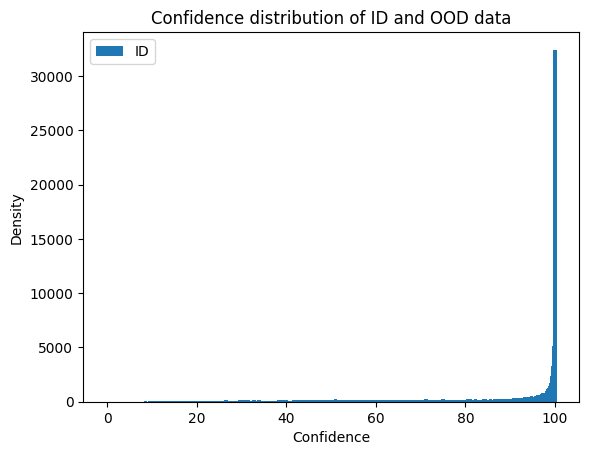

In [73]:
# Plotting the 2 distributions
# plt.bar(np.linspace(0, 100, 1000), ood_dtd_bins[0], label="OOD")
plt.bar(np.linspace(0, 100, 1000),id_data_bins[0], label="ID")
plt.legend()
plt.xlabel("Confidence")
plt.ylabel("Density")
plt.title("Confidence distribution of ID and OOD data")
plt.show()


## Plot Energy Score Distribution

In [6]:
method_name = "ashp"
id_data = np.load(get_top_level_path() + f"/results/imagenet/{method_name}/id_imagenet.npy", allow_pickle=True).item()
ood_dtd = np.load(get_top_level_path() + f"/results/imagenet/{method_name}/ood_dtd.npy", allow_pickle=True).item()
ood_places = np.load(get_top_level_path() + f"/results/imagenet/{method_name}/ood_places.npy", allow_pickle=True).item()
ood_inat = np.load(get_top_level_path() + f"/results/imagenet/{method_name}/ood_inat.npy", allow_pickle=True).item()
ood_sun = np.load(get_top_level_path() + f"/results/imagenet/{method_name}/ood_sun.npy", allow_pickle=True).item()

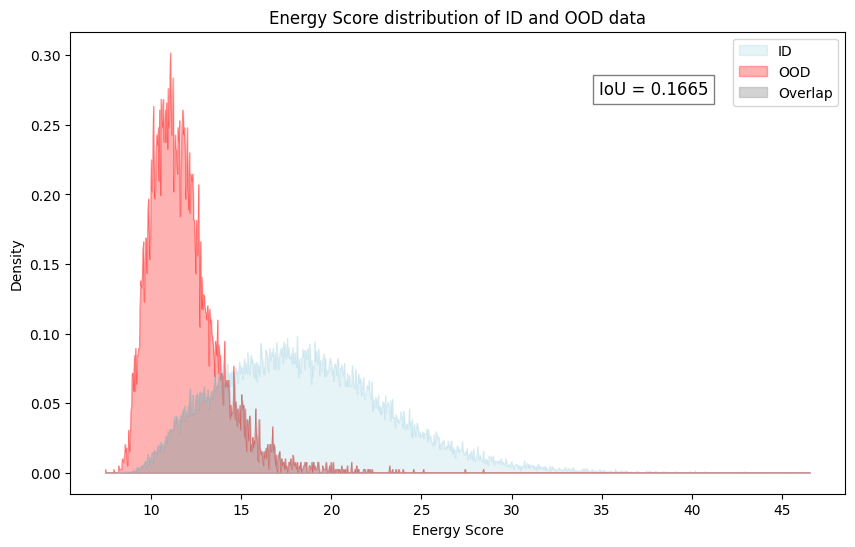

In [27]:
def plot_score_distributions(data_1: np.array, data_2: np.array, title: str, x_label: str, y_label: str, 
                             data_1_label: str, data_2_label: str, range=None, num_bins: int = 1000):
    # Determine range of the histograms
    max_val = max(max(data_1), max(data_2))
    min_val = min(min(data_1), min(data_2))
    range = (min_val, max_val) if range is None else range

    # Calculate histograms and bin edges
    data_1_hist, bin_edges = np.histogram(data_1, bins=num_bins, range=range, density=True)
    data_2_hist, _ = np.histogram(data_2, bins=num_bins, range=range, density=True)

    # Intersection over Union (IoU)
    intersection = np.minimum(data_1_hist, data_2_hist)
    union = np.maximum(data_1_hist, data_2_hist)
    iou = np.sum(intersection) / np.sum(union)

    plt.figure(figsize=(10, 6))

    # Midpoints of bins for plotting
    bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2

    data_1_color = 'lightblue'
    data_2_color = 'red'
    overlap_color = 'darkgray'
    
    plt.fill_between(bin_centers, 0, data_1_hist, color=data_1_color, alpha=0.3, label=data_1_label)
    
    plt.fill_between(bin_centers, 0, data_2_hist, color=data_2_color, alpha=0.3, label=data_2_label)
    
    # Fill overlap area
    plt.fill_between(bin_centers, 0, intersection, color=overlap_color, alpha=0.5, label="Overlap")

    plt.plot(bin_centers, data_1_hist, color=data_1_color, alpha=0.6, linewidth=0.2)
    plt.plot(bin_centers, data_2_hist, color=data_2_color, alpha=0.6, linewidth=0.2)

    # Add IoU text to the plot
    plt.text(0.7 * range[1] + 0.3 * range[0], max(max(data_1_hist), max(data_2_hist)) * 0.9, 
             f"IoU = {iou:.4f}", fontsize=12, color='black', bbox=dict(facecolor='white', alpha=0.5))

    # Add labels, title, and legend
    plt.xlabel(x_label)
    plt.ylabel(y_label)
    plt.title(title)
    plt.legend()
    plt.show()

plot_score_distributions(id_data["energy_score"], ood_inat["energy_score"], "Energy Score distribution of ID and OOD data", "Energy Score", "Density", "ID", "OOD")
